# Chapitre 7 - Cours 2 : optimisme, Cp, AIC, BIC, nombre effectif de paramètres et dimension VC

Le notebook précédent a montré que l'erreur d'apprentissage $\overline{\mathrm{err}}$ est
trop optimiste. Nous quantifions ici cet **optimisme** (sections 7.4 à 7.9 du livre) et en
déduisons des critères analytiques de sélection de modèle :

1. erreur intra-échantillon, optimisme et formule $\omega = \frac2N\sum\mathrm{Cov}(\hat y_i, y_i)$ ;
2. les critères **Cp** et **AIC**, illustrés sur les données de phonèmes (figure 7.4) ;
3. le **nombre effectif de paramètres** $\mathrm{df}(\mathbf S) = \mathrm{trace}(\mathbf S)$ ;
4. le critère **BIC** et son interprétation bayésienne, comparé à AIC ;
5. la **dimension de Vapnik-Chervonenkis** (figures 7.5 et 7.6).

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from esl.plotting import set_style, COLORS, BLUE, ORANGE, GRAY, SEQ, DIV, TWO_CLASS
from esl import datasets
from esl import ch07_selection as sel
set_style()

## 1. Erreur intra-échantillon et optimisme

Dans cette section, les entrées $x_1, \dots, x_N$ sont **fixées** et seules les réponses
sont aléatoires. On imagine de **nouvelles** réponses $Y_i^0$ observées aux mêmes points
$x_i$, indépendantes des $y_i$ mais de même loi. L'**erreur intra-échantillon**
(éq. (7.18) du livre) est

$$
\mathrm{Err}_{\mathrm{in}} = \frac1N \sum_{i=1}^N \mathbb E_{Y^0}\big[L(Y_i^0, \hat f(x_i)) \,\big|\, \mathcal T\big].
$$

Elle diffère de $\mathrm{Err}_{\mathcal T}$ uniquement par le lieu des points test : on
évalue aux points d'apprentissage au lieu de points $X^0$ nouveaux.

On définit l'**optimisme** comme l'écart $\mathrm{op} = \mathrm{Err}_{\mathrm{in}} - \overline{\mathrm{err}}$
(éq. (7.19)), et l'**optimisme moyen** $\omega = \mathbb E_{\mathbf y}(\mathrm{op})$ (éq. (7.20)),
où l'espérance porte sur les réponses d'apprentissage. Pour la perte quadratique (et
d'autres pertes), on a le résultat fondamental (éq. (7.21), démontré dans l'exercice 7.4) :

$$\omega = \frac2N \sum_{i=1}^N \mathrm{Cov}(\hat y_i, y_i).$$

Autrement dit,
$$\mathbb E_{\mathbf y}(\mathrm{Err}_{\mathrm{in}}) = \mathbb E_{\mathbf y}(\overline{\mathrm{err}}) + \frac2N\sum_{i=1}^N \mathrm{Cov}(\hat y_i, y_i). \tag{7.22}$$

> **Intuition.** Plus une observation $y_i$ influence sa propre prédiction $\hat y_i$,
> plus l'erreur d'apprentissage est flatteuse. Un modèle qui interpole ($\hat y_i = y_i$)
> a une covariance maximale $\mathrm{Var}(y_i) = \sigma^2_\varepsilon$ et une erreur
> d'apprentissage nulle.

**Cas linéaire.** Si $\hat{\mathbf y} = \mathbf H\mathbf y$ est un ajustement par
moindres carrés sur $d$ variables (ou fonctions de base) et $Y = f(X) + \varepsilon$ avec
$\mathrm{Var}(\varepsilon) = \sigma_\varepsilon^2$, alors
$\mathrm{Cov}(\hat{\mathbf y}, \mathbf y) = \mathbf H\,\mathrm{Var}(\mathbf y) = \sigma^2_\varepsilon\mathbf H$,
donc $\sum_i \mathrm{Cov}(\hat y_i, y_i) = \sigma^2_\varepsilon\,\mathrm{trace}(\mathbf H) = d\,\sigma^2_\varepsilon$
(éq. (7.23)), et

$$\mathbb E_{\mathbf y}(\mathrm{Err}_{\mathrm{in}}) = \mathbb E_{\mathbf y}(\overline{\mathrm{err}}) + 2\,\frac dN\,\sigma^2_\varepsilon. \tag{7.24}$$

L'optimisme croît **linéairement** avec $d$ et décroît comme $1/N$.

Vérifions (7.24) par simulation : $N = 40$ entrées fixées, $f(x) = \sin(2\pi x_1) + x_2$,
régression polynomiale en $x_1$ de degré variable (avec $x_2$), $\sigma_\varepsilon = 1$.
On estime $\mathbb E(\mathrm{Err}_{\mathrm{in}} - \overline{\mathrm{err}})$ en tirant
beaucoup de vecteurs $\mathbf y$ et, pour chacun, des réponses neuves $\mathbf Y^0$.

In [2]:
rng = np.random.RandomState(0)
N, sig, n_rep = 40, 1.0, 4000
X = rng.rand(N, 2)
fx = np.sin(2 * np.pi * X[:, 0]) + X[:, 1]
degrees = np.arange(1, 11)
opt_mc, d_list = [], []
for deg in degrees:
    B = np.column_stack([X[:, 0] ** j for j in range(1, deg + 1)] + [X[:, 1]])
    H = sel.hat_matrix(B)
    d_list.append(np.trace(H))
    Y = fx + sig * rng.randn(n_rep, N)
    Y0 = fx + sig * rng.randn(n_rep, N)
    Yhat = Y @ H.T
    err = ((Y - Yhat) ** 2).mean(1)
    err_in = ((Y0 - Yhat) ** 2).mean(1)
    opt_mc.append((err_in - err).mean())
d_list = np.array(d_list)

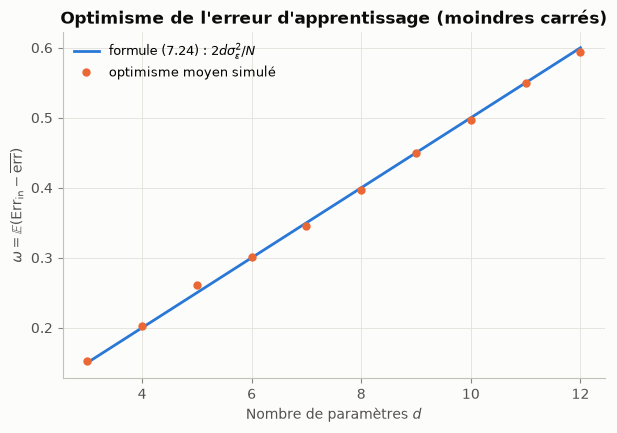

In [3]:
fig, ax = plt.subplots(figsize=(7, 4.5))
ax.plot(d_list, 2 * d_list * sig ** 2 / N, color=BLUE, label=r"formule (7.24) : $2d\sigma_\varepsilon^2/N$")
ax.plot(d_list, opt_mc, "o", color=ORANGE, label="optimisme moyen simulé")
ax.set_xlabel("Nombre de paramètres $d$")
ax.set_ylabel(r"$\omega = \mathbb{E}(\mathrm{Err}_{\mathrm{in}} - \overline{\mathrm{err}})$")
ax.set_title("Optimisme de l'erreur d'apprentissage (moindres carrés)")
ax.legend()
plt.show()

Les points simulés tombent sur la droite $2d\sigma^2_\varepsilon/N$, **quelle que soit**
la qualité du modèle (même les modèles très biaisés de petit degré) : l'optimisme ne
dépend que du nombre de paramètres et du bruit.

## 2. Critères Cp et AIC

L'idée est simple : estimer l'optimisme et l'**ajouter** à l'erreur d'apprentissage.
Avec $d$ paramètres et la perte quadratique, (7.24) conduit à la statistique de Mallows

$$C_p = \overline{\mathrm{err}} + 2\cdot\frac dN\,\hat\sigma^2_\varepsilon, \tag{7.26}$$

où $\hat\sigma^2_\varepsilon$ estime la variance du bruit, typiquement à partir de l'erreur
quadratique moyenne d'un modèle **peu biaisé** (par exemple le modèle complet).

Le **critère d'information d'Akaike** (AIC) généralise cette idée à toute
vraisemblance. Si $\hat\theta$ est l'estimateur du maximum de vraisemblance d'un modèle à
$d$ paramètres et $\mathrm{loglik} = \sum_{i=1}^N \log \Pr_{\hat\theta}(y_i)$, on dispose
de l'approximation asymptotique (éq. (7.27))
$-2\,\mathbb E[\log\Pr_{\hat\theta}(Y)] \approx -\frac2N\mathbb E[\mathrm{loglik}] + 2\frac dN$,
d'où

$$\mathrm{AIC} = -\frac2N\cdot\mathrm{loglik} + 2\cdot\frac dN. \tag{7.29}$$

**Lien avec Cp.** Dans le modèle gaussien de variance $\sigma^2_\varepsilon$ connue,
$$-2\,\mathrm{loglik} = \sum_i \frac{(y_i - \hat f(x_i))^2}{\sigma^2_\varepsilon} + \text{constante}
= \frac{N\,\overline{\mathrm{err}}}{\sigma^2_\varepsilon} + \text{constante},$$
donc $\mathrm{AIC} = \big(\overline{\mathrm{err}} + 2\frac dN\sigma^2_\varepsilon\big)/\sigma^2_\varepsilon + \text{constante}$ :
AIC et Cp sont **équivalents** (même minimiseur). Pour une famille de modèles indexée
par un paramètre de réglage $\alpha$, on minimise
$\mathrm{AIC}(\alpha) = \overline{\mathrm{err}}(\alpha) + 2\frac{d(\alpha)}N\hat\sigma^2_\varepsilon$ (éq. (7.30)).

> **Remarque.** La formule $\sum_i\mathrm{Cov}(\hat y_i, y_i) = d\sigma^2_\varepsilon$
> suppose que les $d$ fonctions de base sont fixées **à l'avance**. Si l'on choisit les
> $d$ meilleures variables parmi $p$ en regardant les données, l'optimisme est plus grand :
> le nombre effectif de paramètres dépasse $d$. Nous le vérifierons plus bas.

### 2.1 Figure 7.4 : AIC pour les données de phonèmes

On reprend l'exemple de la section 5.2.3 : distinguer les phonèmes « aa » et « ao » à
partir du log-périodogramme $x(f)$ mesuré en 256 fréquences. La régression logistique
utilise une **fonction coefficient** lisse
$$\log\frac{\Pr(\text{aa}\mid x)}{\Pr(\text{ao}\mid x)} = \beta_0 + \sum_{f=1}^{256} x(f)\beta(f),
\qquad \beta(f) = \sum_{m=1}^M h_m(f)\,\theta_m,$$
où les $h_m$ forment une base de $M$ splines cubiques naturelles à nœuds équirépartis.
Le modèle est donc une régression logistique sur les $M$ variables dérivées
$\mathbf x^{*} = \mathbf H^T\mathbf x$, avec $d = M + 1$ paramètres (constante comprise).
Pour $M = 256$, on prend $\mathbf H = I$ (aucune contrainte de lissage).

In [4]:
ph = datasets.load_phoneme()
ph = ph[ph["g"].isin(["aa", "ao"])]
Xph = ph.filter(like="x.").to_numpy(float)
yph = (ph["g"] == "aa").to_numpy(int)
rng = np.random.RandomState(0)
perm = rng.permutation(len(yph))
itr, ite = perm[:1000], perm[1000:]
print("apprentissage :", len(itr), "observations ; test :", len(ite))

apprentissage : 1000 observations ; test : 717


On ajuste la régression logistique par l'algorithme de Newton-Raphson (IRLS, section
4.4.1), codé dans `esl.ch07_selection.logistic_regression`. Pour la stabilité numérique,
on orthonormalise d'abord les colonnes de $[\mathbf 1, \mathbf X\mathbf H]$ (décomposition
QR) : cela change la paramétrisation mais **pas** le modèle ajusté.

In [5]:
freqs = np.arange(1, 257) / 256
M_list = [2, 4, 8, 16, 32, 64, 128, 256]
rows = []
for M in M_list:
    Hb = np.eye(256) if M == 256 else sel.natural_spline_basis(freqs, np.linspace(freqs[0], 1, M))
    Z, _ = np.linalg.qr(np.column_stack([np.ones(len(yph)), Xph @ Hb]))
    Z *= np.sqrt(len(yph))
    b = sel.logistic_regression(Z[itr], yph[itr])
    ll_tr = sel.logistic_loglik(Z[itr], yph[itr], b)
    ll_te = sel.logistic_loglik(Z[ite], yph[ite], b)
    d = M + 1
    rows.append(dict(M=M, dev_tr=-2 * ll_tr / len(itr), dev_te=-2 * ll_te / len(ite),
                     aic=sel.aic_loglik(ll_tr, d, len(itr)),
                     mis_tr=np.mean((Z[itr] @ b > 0) != yph[itr]),
                     mis_te=np.mean((Z[ite] @ b > 0) != yph[ite])))
import pandas as pd
tab = pd.DataFrame(rows).set_index("M")
tab.round(3)

,dev_tr,dev_te,aic,mis_tr,mis_te
M,,,,,
2,1.104,1.190,1.110,0.276,0.312
4,1.056,1.096,1.066,0.256,0.264
8,0.877,0.851,0.895,0.209,0.192
16,0.820,0.770,0.854,0.190,0.163
32,0.774,0.767,0.840,0.172,0.166
64,0.722,0.796,0.852,0.165,0.184
128,0.646,0.919,0.904,0.144,0.211
256,0.464,1.634,0.978,0.087,0.238


Pour la perte 0-1, la formule de l'optimisme n'est pas exacte, mais on peut tout de même
l'utiliser comme le fait le livre : $\overline{\mathrm{err}} + 2\frac dN\hat\sigma^2$ avec
$\hat\sigma^2 = \bar p(1-\bar p)$ une estimation grossière de la variance d'une réponse
binaire (ici $\bar p$ est la proportion de « aa »).

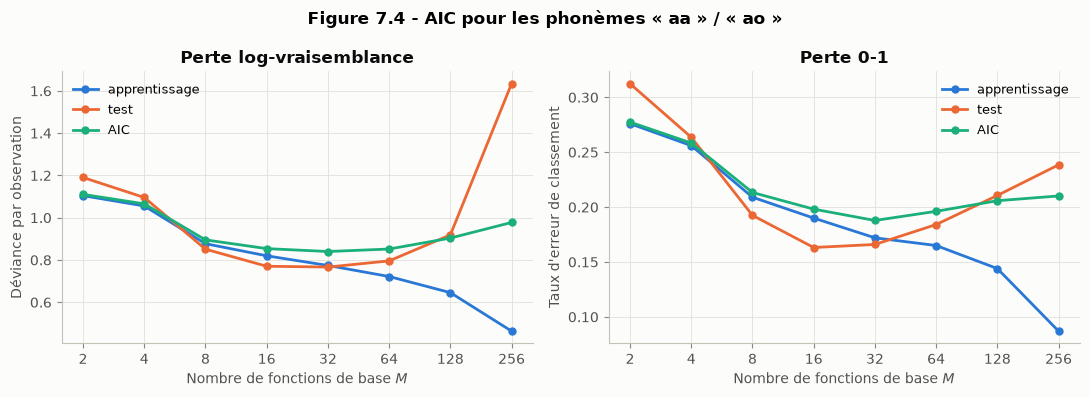

In [6]:
pbar = yph[itr].mean()
tab["aic_01"] = tab["mis_tr"] + 2 * (tab.index + 1) / len(itr) * pbar * (1 - pbar)
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, (tr, te, aic, lab) in zip(axes, [("dev_tr", "dev_te", "aic", "Déviance par observation"),
                                         ("mis_tr", "mis_te", "aic_01", "Taux d'erreur de classement")]):
    ax.plot(M_list, tab[tr], "o-", color=BLUE, label="apprentissage")
    ax.plot(M_list, tab[te], "o-", color=ORANGE, label="test")
    ax.plot(M_list, tab[aic], "o-", color=COLORS[2], label="AIC")
    ax.set_xscale("log", base=2)
    ax.set_xticks(M_list, [str(m) for m in M_list])
    ax.set_xlabel("Nombre de fonctions de base $M$")
    ax.set_ylabel(lab)
    ax.legend()
axes[0].set_title("Perte log-vraisemblance")
axes[1].set_title("Perte 0-1")
fig.suptitle("Figure 7.4 - AIC pour les phonèmes « aa » / « ao »", fontweight="bold")
plt.tight_layout()
plt.show()

In [7]:
print("M minimisant l'AIC (déviance) :", tab["aic"].idxmin(), "; M minimisant l'erreur test (déviance) :", tab["dev_te"].idxmin())

M minimisant l'AIC (déviance) : 32 ; M minimisant l'erreur test (déviance) : 32


L'AIC suit bien la courbe de test **sauf** pour le modèle extrêmement sur-paramétré
$M = 256$ ($257$ paramètres pour $1000$ observations), où l'approximation asymptotique
n'est plus valable. Il conduit à choisir un nombre modéré de fonctions de base, proche de
celui qui minimise l'erreur test.

## 3. Nombre effectif de paramètres

Une méthode d'ajustement est **linéaire** si $\hat{\mathbf y} = \mathbf S\mathbf y$ où la
matrice $N\times N$ $\mathbf S$ dépend des $x_i$ mais pas des $y_i$ (éq. (7.31)) :
régression sur une base fixée, ridge, splines de lissage, $k$ plus proches voisins…
On définit alors le **nombre effectif de paramètres** (ou degrés de liberté effectifs)

$$\mathrm{df}(\mathbf S) = \mathrm{trace}(\mathbf S). \tag{7.32}$$

Pour un projecteur orthogonal sur $M$ fonctions de base, on retrouve $M$.

C'est la bonne quantité à mettre dans Cp : pour un modèle à bruit additif,
$\sum_i \mathrm{Cov}(\hat y_i, y_i) = \mathrm{trace}(\mathbf S)\,\sigma^2_\varepsilon$
(exercice 7.5). Cela motive la définition générale, valable même pour une méthode non
linéaire :

$$\mathrm{df}(\hat{\mathbf y}) = \frac{\sum_{i=1}^N \mathrm{Cov}(\hat y_i, y_i)}{\sigma^2_\varepsilon}. \tag{7.33}$$

Vérifions numériquement l'égalité de (7.32) et (7.33) pour une **spline cubique de
lissage**, qui minimise $\sum_i (y_i - g(x_i))^2 + \lambda\int g''(t)^2\,dt$ (section 5.4) :
sa matrice de lissage $\mathbf S_\lambda$ est calculée par `sel.smoothing_spline_matrix`.

In [8]:
rng = np.random.RandomState(0)
N = 50
xs = np.sort(rng.rand(N))
fs = np.sin(4 * xs)
lams = np.logspace(-7, 0, 8)
df_tr, df_mc = [], []
for lam in lams:
    S = sel.smoothing_spline_matrix(xs, lam)
    df_tr.append(sel.df_trace(S))
    df_mc.append(sel.df_monte_carlo(lambda y: S @ y, fs, sigma=1.0, n_rep=3000, rng=rng))
pd.DataFrame({"lambda": ["%.0e" % l for l in lams], "trace(S)": np.round(df_tr, 2),
              "sum Cov / sigma^2 (simulation)": np.round(df_mc, 2)})

,lambda,trace(S),sum Cov / sigma^2 (simulation)
0,1e-07,34.35,34.26
1,1e-06,24.86,24.93
2,1e-05,16.10,16.11
3,1e-04,9.90,9.95
4,1e-03,6.11,6.13
5,1e-02,3.91,3.91
6,1e-01,2.68,2.71
7,1e+00,2.11,2.05


Les deux colonnes coïncident aux fluctuations de Monte-Carlo près. Quand $\lambda \to 0$
la spline interpole ($\mathrm{df} \to N$) ; quand $\lambda \to \infty$ elle devient la
droite des moindres carrés ($\mathrm{df} \to 2$).

### 3.1 Sélection adaptative : le « vrai » nombre de paramètres dépasse $d$

Utilisons maintenant la définition (7.33) pour une méthode **non linéaire** : la
régression pas à pas ascendante qui choisit $d$ variables parmi $p = 20$. Pour mettre en
évidence l'effet de la sélection, on prend une réponse de **pur bruit**
($f = 0$, $\sigma_\varepsilon = 1$), $N = 50$, et l'on estime
$\sum_i\mathrm{Cov}(\hat y_i, y_i)/\sigma^2_\varepsilon$ par simulation.

In [9]:
rng = np.random.RandomState(1)
N, P, n_rep, dmax = 50, 20, 400, 10
Xa = rng.randn(N, P)
Y = rng.randn(n_rep, N)
fits = np.zeros((n_rep, dmax + 1, N))
for r in range(n_rep):
    order = sel.forward_stepwise(Xa, Y[r], max_size=dmax)
    for d in range(dmax + 1):
        fits[r, d] = sel.ols_fit_predict(Xa[:, order[:d]], Y[r], Xa[:, order[:d]]) if d else Y[r].mean()
cov = ((Y - Y.mean(0))[:, None, :] * (fits - fits.mean(0))).sum(0) / (n_rep - 1)
df_adapt = cov.sum(1)   # sigma = 1

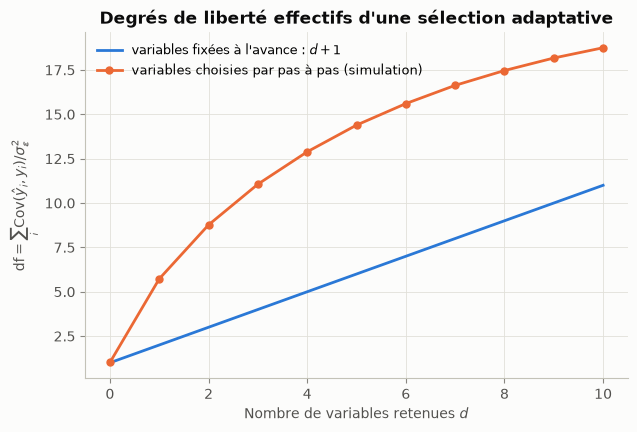

In [10]:
dd = np.arange(dmax + 1)
fig, ax = plt.subplots(figsize=(7, 4.5))
ax.plot(dd, dd + 1, color=BLUE, label="variables fixées à l'avance : $d+1$")
ax.plot(dd, df_adapt, "o-", color=ORANGE, label="variables choisies par pas à pas (simulation)")
ax.set_xlabel("Nombre de variables retenues $d$")
ax.set_ylabel(r"$\mathrm{df} = \sum_i \mathrm{Cov}(\hat y_i, y_i)/\sigma_\varepsilon^2$")
ax.set_title("Degrés de liberté effectifs d'une sélection adaptative")
ax.legend()
plt.show()

Choisir les variables en regardant les données « consomme » des degrés de liberté
supplémentaires : avec $d = 1$ variable choisie parmi 20, le nombre effectif de paramètres
est déjà bien supérieur à 2. Utiliser Cp avec $d$ naïf sous-estimerait l'optimisme.

## 4. Le critère BIC et l'approche bayésienne

Le **critère d'information bayésien** s'applique, comme l'AIC, aux ajustements par
maximum de vraisemblance :

$$\mathrm{BIC} = -2\cdot\mathrm{loglik} + (\log N)\cdot d. \tag{7.35}$$

Dans le cas gaussien à variance connue, comme plus haut,
$\mathrm{BIC} = \frac N{\sigma^2_\varepsilon}\big[\overline{\mathrm{err}} + (\log N)\frac dN\sigma^2_\varepsilon\big]$
(éq. (7.36)) : c'est l'AIC avec le facteur $2$ remplacé par $\log N$. Dès que
$N > e^2 \approx 7{,}4$, le BIC **pénalise plus** la complexité et favorise des modèles
plus simples.

**Motivation bayésienne.** On se donne des modèles candidats $\mathcal M_1, \dots, \mathcal M_M$,
de paramètres $\theta_m$, avec des lois a priori $\Pr(\theta_m\mid\mathcal M_m)$. Par la
formule de Bayes, la probabilité a posteriori d'un modèle au vu des données $\mathbf Z$ est

$$\Pr(\mathcal M_m\mid\mathbf Z) \propto \Pr(\mathcal M_m)\,\Pr(\mathbf Z\mid\mathcal M_m)
= \Pr(\mathcal M_m)\int \Pr(\mathbf Z\mid\theta_m, \mathcal M_m)\Pr(\theta_m\mid\mathcal M_m)\,d\theta_m. \tag{7.37}$$

Le rapport $\Pr(\mathbf Z\mid\mathcal M_m)/\Pr(\mathbf Z\mid\mathcal M_\ell)$ s'appelle le
**facteur de Bayes** (éq. (7.39)).

L'intégrale (la « vraisemblance marginale ») n'est pas explicite en général. Quand $N$ est
grand, la vraisemblance est très concentrée autour de $\hat\theta_m$ et l'on peut
l'approcher par une gaussienne (**approximation de Laplace** : développement de Taylor à
l'ordre 2 du logarithme autour du maximum). Le volume de cette gaussienne en dimension
$d_m$ décroît comme $N^{-d_m/2}$, ce qui donne (éq. (7.40))

$$\log\Pr(\mathbf Z\mid\mathcal M_m) = \log\Pr(\mathbf Z\mid\hat\theta_m, \mathcal M_m) - \frac{d_m}2\log N + O(1).$$

Avec un a priori uniforme sur les modèles, maximiser la probabilité a posteriori revient
donc (au $O(1)$ près) à **minimiser le BIC**. On en déduit même des probabilités a
posteriori approchées $\Pr(\mathcal M_m\mid\mathbf Z) \approx e^{-\mathrm{BIC}_m/2}\big/\sum_\ell e^{-\mathrm{BIC}_\ell/2}$ (éq. (7.41)).

> **Remarque (longueur de description minimale).** La section 7.8 du livre présente le
> principe MDL : choisir le modèle qui permet de **coder** les données avec le moins de
> bits, en comptant le coût du codage des paramètres et celui des résidus. La longueur de
> description optimale d'un message de probabilité $p$ étant $-\log_2 p$ bits, minimiser la
> longueur totale revient à maximiser une probabilité a posteriori : MDL conduit au même
> critère que le BIC.

### 4.1 AIC contre BIC : convergence de la sélection

Comparons les deux critères sur des modèles linéaires emboîtés $d = 1, \dots, 10$ quand
le **vrai** modèle utilise les $3$ premières variables ($\beta = (1;\ 0{,}5;\ 0{,}25)$,
$\sigma_\varepsilon = 1$ supposé connu), pour des tailles d'échantillon croissantes.

In [11]:
rng = np.random.RandomState(0)
Ns = [20, 50, 100, 200, 500, 1000, 2000]
P, n_rep, beta_true = 10, 300, np.r_[1.0, 0.5, 0.25, np.zeros(7)]
choice = {"AIC": np.zeros((len(Ns), n_rep), int), "BIC": np.zeros((len(Ns), n_rep), int)}
for a, n in enumerate(Ns):
    for r in range(n_rep):
        X = rng.randn(n, P)
        y = X @ beta_true + rng.randn(n)
        Q, _ = np.linalg.qr(X)
        z = Q.T @ y
        rss = y @ y - np.cumsum(z ** 2)          # RSS des modèles emboîtés d = 1..P
        err = rss / n
        dgrid = np.arange(1, P + 1)
        choice["AIC"][a, r] = dgrid[np.argmin(sel.cp_statistic(err, dgrid, 1.0, n))]
        choice["BIC"][a, r] = dgrid[np.argmin(sel.bic_gaussian(err, dgrid, 1.0, n))]

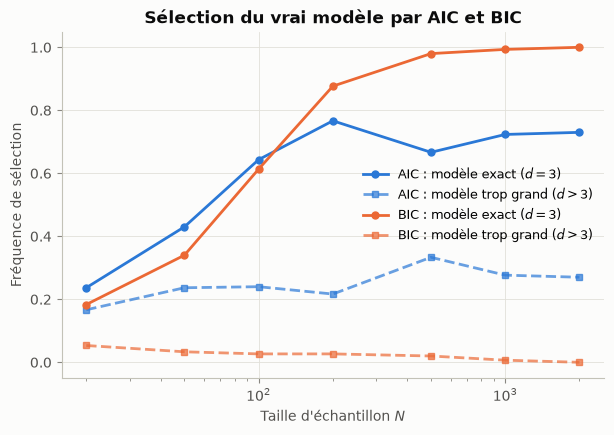

In [12]:
fig, ax = plt.subplots(figsize=(7, 4.5))
for name, c in [("AIC", BLUE), ("BIC", ORANGE)]:
    ax.plot(Ns, (choice[name] == 3).mean(1), "o-", color=c, label="%s : modèle exact ($d=3$)" % name)
    ax.plot(Ns, (choice[name] > 3).mean(1), "s--", color=c, alpha=0.7, label="%s : modèle trop grand ($d>3$)" % name)
ax.set_xscale("log")
ax.set_xlabel("Taille d'échantillon $N$")
ax.set_ylabel("Fréquence de sélection")
ax.set_title("Sélection du vrai modèle par AIC et BIC")
ax.legend()
plt.show()

Quand $N$ grandit, le BIC choisit le vrai modèle avec une probabilité qui tend vers 1 :
il est **convergent**. L'AIC garde une probabilité non négligeable (environ 30 % ici)
de choisir un modèle trop grand. Pour de petits échantillons, en revanche, le BIC tend à
choisir des modèles trop **simples** (il rate les petits coefficients). Il n'y a pas de
gagnant universel : l'AIC vise une bonne **prédiction**, le BIC l'identification du
**vrai** modèle.

## 5. Dimension de Vapnik-Chervonenkis

Pour les critères précédents, il faut connaître le nombre (effectif) de paramètres. La
théorie de Vapnik-Chervonenkis (VC) propose une mesure de complexité plus générale. On
considère une classe de fonctions indicatrices $\{f(x, \alpha)\}$ à valeurs dans
$\{0, 1\}$.

* Un ensemble de points est **pulvérisé** (*shattered*) par la classe si, pour **tout**
  étiquetage binaire de ces points, un membre de la classe les sépare parfaitement.
* La **dimension VC** de la classe est le plus grand nombre de points (dans une
  configuration bien choisie) qui peuvent être pulvérisés.

**Figure 7.6 : droites du plan.** Les indicatrices de demi-plans
$I(\alpha_0 + \alpha_1^T x > 0)$, $x\in\mathbb R^2$, pulvérisent 3 points non alignés.
Pour chacun des $2^3 = 8$ étiquetages, il suffit de résoudre le système linéaire
$\alpha_0 + \alpha_1^Tx_i = \pm1$ (3 équations, 3 inconnues, inversible car les points ne
sont pas alignés) : le signe de la fonction affine obtenue reproduit l'étiquetage.

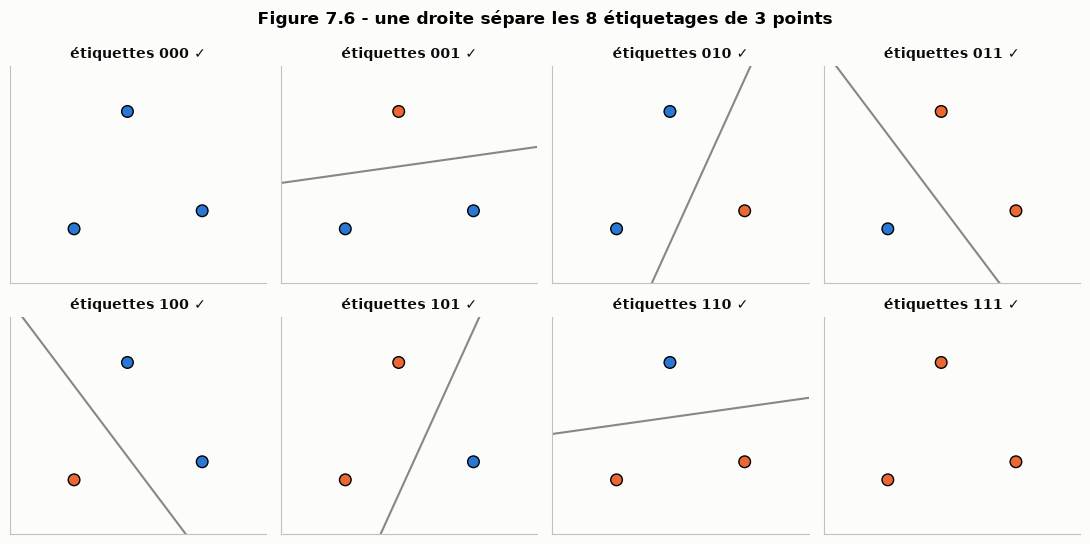

In [13]:
import itertools
pts = np.array([[0.2, 0.2], [0.8, 0.3], [0.45, 0.85]])
A = np.column_stack([np.ones(3), pts])
gx = np.linspace(-0.1, 1.1, 2)
fig, axes = plt.subplots(2, 4, figsize=(11, 5.5))
for ax, lab in zip(axes.ravel(), itertools.product([0, 1], repeat=3)):
    lab = np.array(lab)
    w = np.linalg.solve(A, 2 * lab - 1.0)
    if abs(w[2]) > 1e-12:            # droite w0 + w1 x1 + w2 x2 = 0
        ax.plot(gx, -(w[0] + w[1] * gx) / w[2], color=GRAY, lw=1.5)
    elif abs(w[1]) > 1e-12:
        ax.axvline(-w[0] / w[1], color=GRAY, lw=1.5)
    # sinon (étiquetage constant) : fonction constante, tous les points du même côté
    ok = np.array_equal((A @ w > 0).astype(int), lab)
    ax.scatter(pts[:, 0], pts[:, 1], c=lab, cmap=TWO_CLASS, vmin=0, vmax=1, s=70, edgecolor="k", zorder=3)
    ax.set_xlim(-0.1, 1.1); ax.set_ylim(-0.1, 1.1)
    ax.set_xticks([]); ax.set_yticks([])
    ax.set_title("étiquettes %s %s" % ("".join(map(str, lab)), "✓" if ok else "✗"), fontsize=10)
fig.suptitle("Figure 7.6 - une droite sépare les 8 étiquetages de 3 points", fontweight="bold")
plt.tight_layout()
plt.show()

Pour les étiquetages constants (000 et 111), la solution est une fonction constante :
n'importe quelle droite éloignée des trois points convient. En revanche, **aucune** configuration de 4 points n'est pulvérisée par les
droites : soit un point est dans l'enveloppe convexe des trois autres (on ne peut pas
l'isoler), soit les 4 points forment un quadrilatère convexe et l'étiquetage « en X »
(sommets opposés de même classe, comme le problème du OU exclusif) est impossible. La
dimension VC des droites du plan est donc 3 ; plus généralement celle des hyperplans de
$\mathbb R^p$ est $p + 1$, le nombre de paramètres.

**Figure 7.5 : une classe à un seul paramètre mais de dimension VC infinie.** La classe
$\{I(\sin(\alpha x) > 0),\ \alpha\in\mathbb R\}$ n'a qu'un paramètre, mais en augmentant
la fréquence $\alpha$ on peut séparer n'importe quel nombre de points (exercice 7.8).

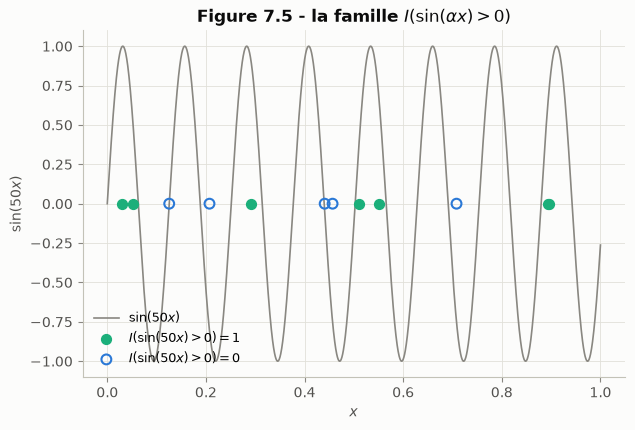

In [14]:
rng = np.random.RandomState(3)
xx = np.linspace(0, 1, 2000)
xp = np.sort(rng.rand(12))
lab = (np.sin(50 * xp) > 0).astype(int)
fig, ax = plt.subplots(figsize=(7, 4.5))
ax.plot(xx, np.sin(50 * xx), color=GRAY, lw=1.2, label=r"$\sin(50x)$")
ax.scatter(xp[lab == 1], np.zeros(lab.sum()), color=COLORS[2], s=50, zorder=3, label=r"$I(\sin(50x)>0) = 1$")
ax.scatter(xp[lab == 0], np.zeros((1 - lab).sum()), facecolor="none", edgecolor=BLUE, s=50, lw=1.5, zorder=3,
           label=r"$I(\sin(50x)>0) = 0$")
ax.set_xlabel("$x$")
ax.set_ylabel(r"$\sin(50x)$")
ax.set_title("Figure 7.5 - la famille $I(\\sin(\\alpha x) > 0)$")
ax.legend(loc="lower left")
plt.show()

**Bornes VC.** Si l'on ajuste $N$ points avec une classe de dimension VC $h$, Vapnik
montre qu'avec probabilité au moins $1 - \eta$, **simultanément** pour toutes les
fonctions de la classe (éq. (7.46), cas de la classification binaire)

$$\mathrm{Err}_{\mathcal T} \leq \overline{\mathrm{err}} + \frac\epsilon2\Big(1 + \sqrt{1 + \frac{4\,\overline{\mathrm{err}}}\epsilon}\Big),
\qquad \epsilon = a_1\,\frac{h[\log(a_2N/h) + 1] - \log(\eta/4)}N,$$

avec des constantes $0 < a_1 \leq 4$, $0 < a_2 \leq 2$. L'optimisme croît avec $h$ et
décroît avec $N$, qualitativement comme le $d/N$ de l'AIC. La **minimisation du risque
structurel** (SRM) ajuste une suite de modèles emboîtés de dimensions VC croissantes et
retient celui dont la borne est la plus petite. Ces bornes sont souvent très
pessimistes, et la dimension VC est difficile à calculer en pratique.

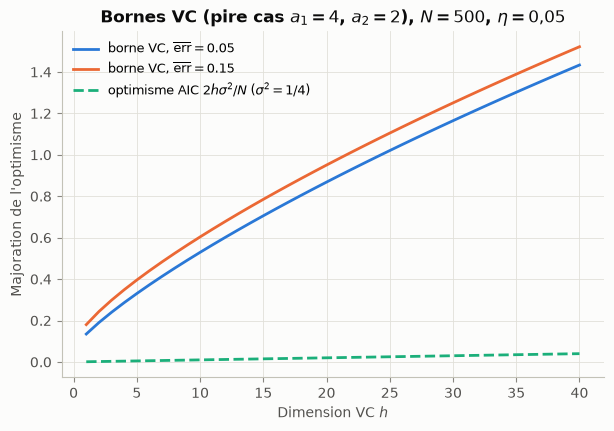

In [15]:
h_grid = np.arange(1, 41)
Nv, eta = 500, 0.05
eps = 4 * (h_grid * (np.log(2 * Nv / h_grid) + 1) - np.log(eta / 4)) / Nv
fig, ax = plt.subplots(figsize=(7, 4.5))
for e0, c in zip([0.05, 0.15], [BLUE, ORANGE]):
    bound = e0 + eps / 2 * (1 + np.sqrt(1 + 4 * e0 / eps))
    ax.plot(h_grid, bound - e0, color=c, label=r"borne VC, $\overline{\mathrm{err}} = %.2f$" % e0)
ax.plot(h_grid, 2 * h_grid / Nv * 0.25, color=COLORS[2], ls="--", label=r"optimisme AIC $2h\sigma^2/N$ ($\sigma^2 = 1/4$)")
ax.set_xlabel("Dimension VC $h$")
ax.set_ylabel("Majoration de l'optimisme")
ax.set_title("Bornes VC (pire cas $a_1=4$, $a_2=2$), $N=500$, $\\eta=0{,}05$")
ax.legend()
plt.show()

La borne VC (au pire cas) est beaucoup plus grande que la correction d'AIC - elle
dépasse même 1 dès $h \approx 20$ : la majoration de $\mathrm{Err}_{\mathcal T}$ devient alors triviale pour un taux d'erreur. Elle est
**uniforme** sur toute la classe et vaut avec grande probabilité, alors que l'AIC ne
corrige qu'en moyenne pour un modèle fixé. Le livre (section 7.9.1) montre que, pour la
sélection de modèle, SRM se comporte comparablement à AIC et BIC sur les exemples de la
figure 7.3.

## 6. Bilan

> **À retenir.**
> * Optimisme moyen : $\omega = \frac2N\sum_i\mathrm{Cov}(\hat y_i, y_i)$ ; pour un
>   ajustement linéaire à $d$ paramètres, $\omega = 2d\sigma^2_\varepsilon/N$.
> * $C_p = \overline{\mathrm{err}} + 2\frac dN\hat\sigma^2_\varepsilon$ ; l'AIC
>   $= -\frac2N\mathrm{loglik} + 2\frac dN$ en est la version vraisemblance.
> * Pour un lisseur linéaire, $d$ est remplacé par $\mathrm{df}(\mathbf S) = \mathrm{trace}(\mathbf S)$ ;
>   la définition générale $\mathrm{df} = \sum_i\mathrm{Cov}(\hat y_i, y_i)/\sigma^2_\varepsilon$
>   montre qu'une sélection adaptative coûte plus que $d$ paramètres.
> * $\mathrm{BIC} = -2\,\mathrm{loglik} + (\log N)d$ approxime la probabilité a posteriori
>   d'un modèle ; il est convergent mais choisit des modèles plus simples que l'AIC.
> * La dimension VC mesure la richesse d'une classe (et non son nombre de paramètres) :
>   les hyperplans de $\mathbb R^p$ ont dimension $p+1$, la famille $I(\sin\alpha x > 0)$
>   une dimension infinie.